In [1]:
# Walmart Enterprise Analytics
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load all four datasets

train = pd.read_csv("data/train.csv")
stores = pd.read_csv("data/stores.csv")
features = pd.read_csv("data/features.csv")
test = pd.read_csv("data/test.csv")

# Display dataset dimensions

print("Datasets loaded successfully!")
print("------------------------------")
print("Train dataset:", train.shape)
print("Stores dataset:", stores.shape)
print("Features dataset:", features.shape)
print("Test dataset:", test.shape)

Datasets loaded successfully!
------------------------------
Train dataset: (421570, 5)
Stores dataset: (45, 3)
Features dataset: (8190, 12)
Test dataset: (115064, 4)


In [2]:
# ==========================================
# DATA CLEANING AND VALIDATION
# ==========================================

# Convert Date columns to datetime

train["Date"] = pd.to_datetime(train["Date"])
features["Date"] = pd.to_datetime(features["Date"])
test["Date"] = pd.to_datetime(test["Date"])

# Check duplicate records

print("DUPLICATE RECORDS")
print("Train:", train.duplicated().sum())
print("Stores:", stores.duplicated().sum())
print("Features:", features.duplicated().sum())
print("Test:", test.duplicated().sum())

# Check missing values

print("\nMISSING VALUES - TRAIN")
print(train.isnull().sum())

print("\nMISSING VALUES - STORES")
print(stores.isnull().sum())

print("\nMISSING VALUES - FEATURES")
print(features.isnull().sum())

# ==========================================
# DATA INTEGRATION
# ==========================================

# Merge sales data with store information

walmart = train.merge(
    stores,
    on="Store",
    how="left",
    validate="many_to_one"
)

# Merge with external business factors

walmart = walmart.merge(
    features,
    on=["Store", "Date", "IsHoliday"],
    how="left",
    validate="many_to_one"
)

# ==========================================
# FINAL DATA VALIDATION
# ==========================================

print("\nFINAL DATASET VALIDATION")

print("Total Records:", len(walmart))
print("Total Stores:", walmart["Store"].nunique())
print("Total Departments:", walmart["Dept"].nunique())
print("Total Sales:", f"${walmart['Weekly_Sales'].sum():,.2f}")
print("Start Date:", walmart["Date"].min())
print("End Date:", walmart["Date"].max())
print("Unmatched Stores:", walmart["Type"].isnull().sum())
print("Missing Temperature:", walmart["Temperature"].isnull().sum())

print("\nMERGED DATASET DIMENSIONS")
print(walmart.shape)

print("\nFIRST FIVE RECORDS")
display(walmart.head())

DUPLICATE RECORDS
Train: 0
Stores: 0
Features: 0
Test: 0

MISSING VALUES - TRAIN
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

MISSING VALUES - STORES
Store    0
Type     0
Size     0
dtype: int64

MISSING VALUES - FEATURES
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64

FINAL DATASET VALIDATION
Total Records: 421570
Total Stores: 45
Total Departments: 81
Total Sales: $6,737,218,987.11
Start Date: 2010-02-05 00:00:00
End Date: 2012-10-26 00:00:00
Unmatched Stores: 0
Missing Temperature: 0

MERGED DATASET DIMENSIONS
(421570, 16)

FIRST FIVE RECORDS


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106


In [3]:
# ==========================================
# EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

# Create additional time-based columns

walmart["Year"] = walmart["Date"].dt.year
walmart["Month"] = walmart["Date"].dt.month
walmart["Month_Name"] = walmart["Date"].dt.month_name()

# 1. Overall sales KPIs

print("OVERALL SALES PERFORMANCE")
print("Total Sales:", f"${walmart['Weekly_Sales'].sum():,.2f}")
print("Average Sales per Record:", f"${walmart['Weekly_Sales'].mean():,.2f}")
print("Total Stores:", walmart["Store"].nunique())
print("Total Departments:", walmart["Dept"].nunique())

# 2. Statistical summary

print("\nSTATISTICAL SUMMARY")
display(walmart["Weekly_Sales"].describe().round(2))

# 3. Sales by store type

print("\nSALES BY STORE TYPE")

store_type_sales = walmart.groupby("Type").agg(
    Total_Sales=("Weekly_Sales", "sum"),
    Average_Sales=("Weekly_Sales", "mean"),
    Number_of_Stores=("Store", "nunique")
)

store_type_sales["Sales_Share_Percentage"] = (
    store_type_sales["Total_Sales"]
    / walmart["Weekly_Sales"].sum() * 100
)

display(store_type_sales.round(2))

# 4. Holiday vs non-holiday sales

print("\nHOLIDAY SALES PERFORMANCE")

holiday_sales = walmart.groupby("IsHoliday").agg(
    Total_Sales=("Weekly_Sales", "sum"),
    Average_Sales=("Weekly_Sales", "mean"),
    Total_Records=("Weekly_Sales", "count")
)

display(holiday_sales.round(2))

# 5. Top 10 performing departments

print("\nTOP 10 DEPARTMENTS")

top_departments = (
    walmart.groupby("Dept")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_departments.round(2))

# 6. Top 10 performing stores

print("\nTOP 10 STORES")

top_stores = (
    walmart.groupby("Store")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_stores.round(2))

# 7. Monthly sales trends

monthly_sales = (
    walmart.groupby(
        walmart["Date"].dt.to_period("M")
    )["Weekly_Sales"]
    .sum()
)

print("\nMONTHLY SALES TRENDS")
display(monthly_sales.round(2))

print("\nExploratory Data Analysis Completed!")

OVERALL SALES PERFORMANCE
Total Sales: $6,737,218,987.11
Average Sales per Record: $15,981.26
Total Stores: 45
Total Departments: 81

STATISTICAL SUMMARY


count    421570.00
mean      15981.26
std       22711.18
min       -4988.94
25%        2079.65
50%        7612.03
75%       20205.85
max      693099.36
Name: Weekly_Sales, dtype: float64


SALES BY STORE TYPE


,Total_Sales,Average_Sales,Number_of_Stores,Sales_Share_Percentage
Type,,,,
A,4.331015e+09,20099.57,22,64.28
B,2.000701e+09,12237.08,17,29.70
C,4.055035e+08,9519.53,6,6.02



HOLIDAY SALES PERFORMANCE


,Total_Sales,Average_Sales,Total_Records
IsHoliday,,,
False,6.231919e+09,15901.45,391909
True,5.052996e+08,17035.82,29661


... (3 outputs left out)

Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
10    2.716177e+08
27    2.538559e+08
6     2.237561e+08
1     2.224028e+08
39    2.074455e+08
Name: Weekly_Sales, dtype: float64


MONTHLY SALES TRENDS


Date
2010-02    1.903330e+08
2010-03    1.819198e+08
2010-04    2.314124e+08
2010-05    1.867109e+08
2010-06    1.922462e+08
2010-07    2.325801e+08
2010-08    1.876401e+08
2010-09    1.772679e+08
2010-10    2.171618e+08
2010-11    2.028534e+08
2010-12    2.887605e+08
2011-01    1.637040e+08
2011-02    1.863313e+08
2011-03    1.793564e+08
2011-04    2.265265e+08
2011-05    1.816482e+08
2011-06    1.897734e+08
2011-07    2.299114e+08
2011-08    1.885993e+08
2011-09    2.208477e+08
2011-10    1.832613e+08
2011-11    2.101624e+08
2011-12    2.880781e+08
2012-01    1.688945e+08
2012-02    1.920636e+08
2012-03    2.315097e+08
2012-04    1.889209e+08
2012-05    1.887665e+08
2012-06    2.406103e+08
2012-07    1.875095e+08
2012-08    2.368508e+08
2012-09    1.806455e+08
2012-10    1.843617e+08
Freq: M, Name: Weekly_Sales, dtype: float64


Exploratory Data Analysis Completed!


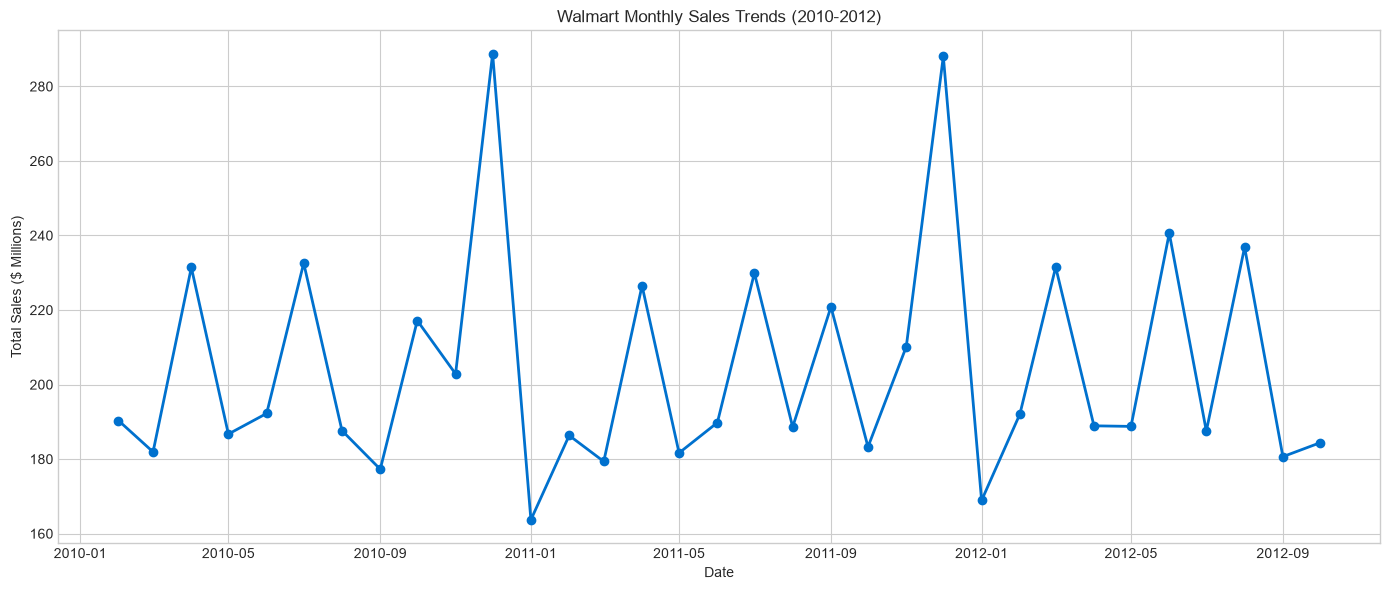

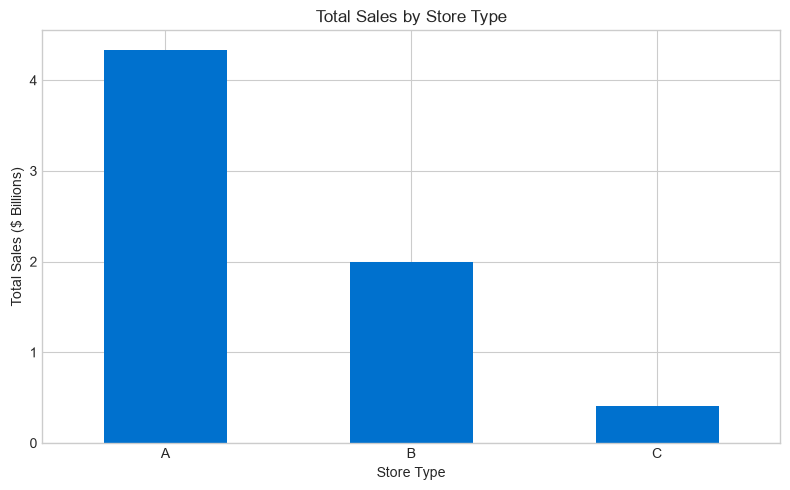

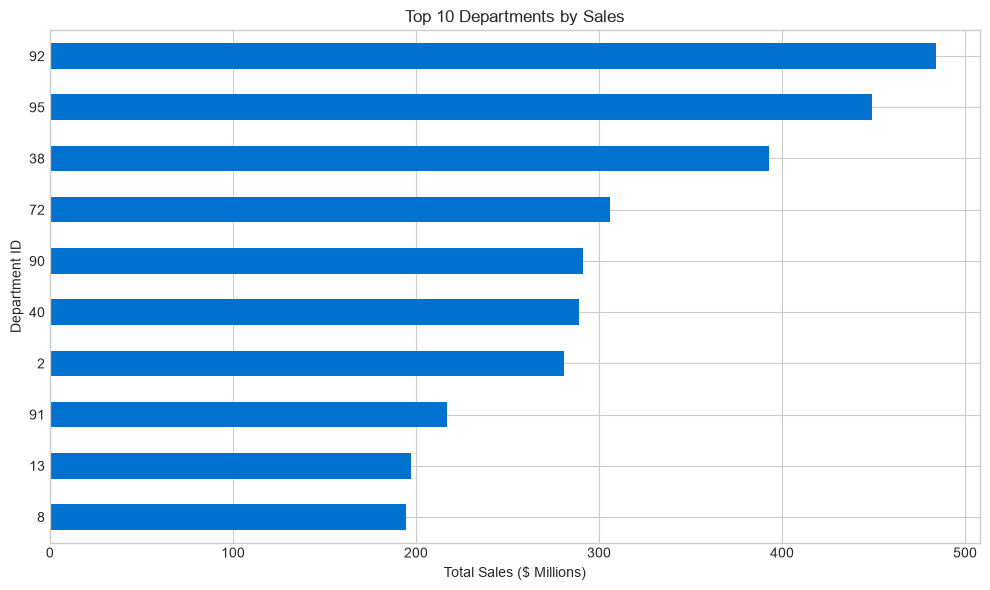

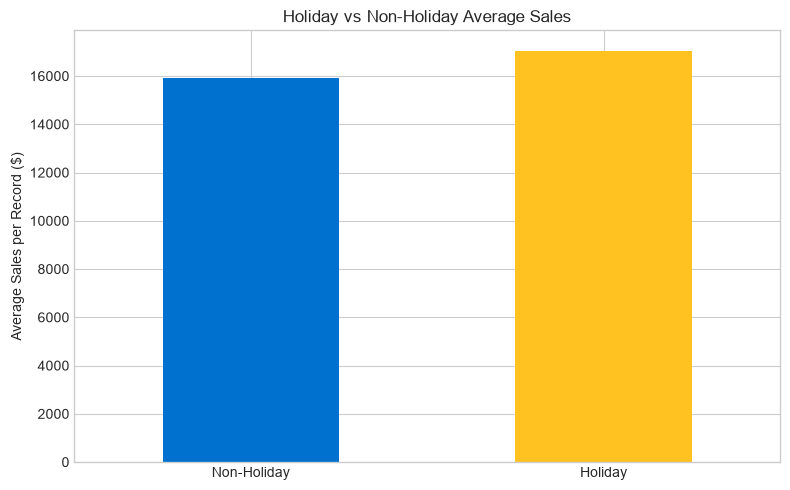

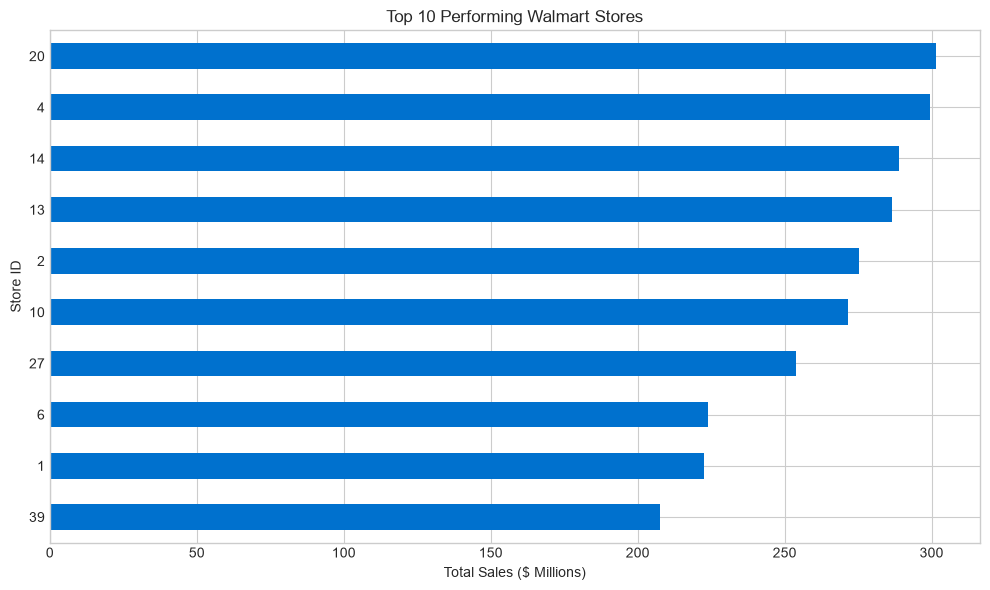

All five visualizations created successfully!


In [4]:
# STEP 3: DATA VISUALIZATION

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load datasets
sales = pd.read_csv("data/train.csv", parse_dates=["Date"])
stores = pd.read_csv("data/stores.csv")

visual_data = sales.merge(stores, on="Store", how="left")

# Create folder for charts
os.makedirs("visualizations", exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
color = "#0071CE"

# 1. Monthly Sales Trend
monthly = visual_data.groupby(
    visual_data["Date"].dt.to_period("M")
)["Weekly_Sales"].sum()

plt.figure(figsize=(14, 6))
plt.plot(monthly.index.to_timestamp(),
         monthly.values / 1e6,
         color=color, linewidth=2, marker="o")
plt.title("Walmart Monthly Sales Trends (2010-2012)")
plt.xlabel("Date")
plt.ylabel("Total Sales ($ Millions)")
plt.tight_layout()
plt.savefig("visualizations/monthly_sales.png", dpi=300)
plt.show()

# 2. Sales by Store Type
store_type = visual_data.groupby("Type")["Weekly_Sales"].sum()

plt.figure(figsize=(8, 5))
(store_type / 1e9).plot(kind="bar", color=color)
plt.title("Total Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Total Sales ($ Billions)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/store_type_sales.png", dpi=300)
plt.show()

# 3. Top 10 Departments
departments = visual_data.groupby("Dept")[
    "Weekly_Sales"
].sum().nlargest(10).sort_values()

plt.figure(figsize=(10, 6))
(departments / 1e6).plot(kind="barh", color=color)
plt.title("Top 10 Departments by Sales")
plt.xlabel("Total Sales ($ Millions)")
plt.ylabel("Department ID")
plt.tight_layout()
plt.savefig("visualizations/top_departments.png", dpi=300)
plt.show()

# 4. Holiday vs Non-Holiday Average Sales
holiday = visual_data.groupby("IsHoliday")[
    "Weekly_Sales"
].mean()

holiday.index = ["Holiday" if x else "Non-Holiday"
                 for x in holiday.index]

plt.figure(figsize=(8, 5))
holiday.plot(kind="bar", color=["#0071CE", "#FFC220"])
plt.title("Holiday vs Non-Holiday Average Sales")
plt.ylabel("Average Sales per Record ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/holiday_sales.png", dpi=300)
plt.show()

# 5. Top 10 Performing Stores
top_stores = visual_data.groupby("Store")[
    "Weekly_Sales"
].sum().nlargest(10).sort_values()

plt.figure(figsize=(10, 6))
(top_stores / 1e6).plot(kind="barh", color=color)
plt.title("Top 10 Performing Walmart Stores")
plt.xlabel("Total Sales ($ Millions)")
plt.ylabel("Store ID")
plt.tight_layout()
plt.savefig("visualizations/top_stores.png", dpi=300)
plt.show()

print("All five visualizations created successfully!")

In [5]:
# ==========================================
# MACHINE LEARNING - DATA PREPARATION
# ==========================================

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create a separate dataset for machine learning
ml_data = walmart.copy()

# Convert Date column
ml_data["Date"] = pd.to_datetime(ml_data["Date"])

# Feature engineering
ml_data["Year"] = ml_data["Date"].dt.year
ml_data["Month"] = ml_data["Date"].dt.month
ml_data["Week"] = ml_data["Date"].dt.isocalendar().week.astype(int)
ml_data["Quarter"] = ml_data["Date"].dt.quarter

# Convert holiday values into numbers
ml_data["IsHoliday"] = (
    ml_data["IsHoliday"].astype(str)
    .str.lower().map({"true": 1, "false": 0})
)

# Convert store types into numerical values
ml_data["Type"] = ml_data["Type"].map({
    "A": 1,
    "B": 2,
    "C": 3
})

# Select model features
features = [
    "Store",
    "Dept",
    "Type",
    "Size",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "IsHoliday",
    "Year",
    "Month",
    "Week",
    "Quarter"
]

target = "Weekly_Sales"

# Remove records missing required model inputs
ml_data = ml_data.dropna(subset=features + [target])

# Sort data chronologically
ml_data = ml_data.sort_values("Date")

# Time-based training and testing split
train_data = ml_data[ml_data["Date"] < "2012-07-01"]
test_data = ml_data[ml_data["Date"] >= "2012-07-01"]

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

# Display results
print("MACHINE LEARNING DATA PREPARATION")
print("---------------------------------")
print("Total Records:", len(ml_data))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Number of Features:", len(features))

print("\nTraining Period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting Period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

print("\nMissing Feature Values:")
print(ml_data[features].isnull().sum())

print("\nData Preparation Completed Successfully!")

MACHINE LEARNING DATA PREPARATION
---------------------------------
Total Records: 421570
Training Records: 371242
Testing Records: 50328
Number of Features: 13

Training Period:
2010-02-05 00:00:00 to 2012-06-29 00:00:00

Testing Period:
2012-07-06 00:00:00 to 2012-10-26 00:00:00

Missing Feature Values:
Store           0
Dept            0
Type            0
Size            0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
IsHoliday       0
Year            0
Month           0
Week            0
Quarter         0
dtype: int64

Data Preparation Completed Successfully!


In [6]:
# ==========================================
# MACHINE LEARNING - MODEL TRAINING
# ==========================================

# 1. Baseline model
print("Creating Baseline Model...")

historical_avg = train_data.groupby(
    ["Store", "Dept"]
)["Weekly_Sales"].mean()

baseline_predictions = (
    test_data.set_index(["Store", "Dept"])
    .index.map(historical_avg)
)

baseline_predictions = pd.Series(
    baseline_predictions, dtype=float
).fillna(y_train.mean()).to_numpy()

# 2. Random Forest model
print("Training Random Forest Model...")

rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=2
)

rf_model.fit(X_train, y_train)

# 3. Generate predictions
rf_predictions = rf_model.predict(X_test)

# 4. Model evaluation
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2_Score": r2_score(actual, predicted)
    }

# 5. Compare model performance
model_results = pd.DataFrame([
    evaluate_model(
        "Baseline Model",
        y_test,
        baseline_predictions
    ),
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
])

print("\nMODEL PERFORMANCE COMPARISON")
display(model_results.round(4))

# 6. Calculate improvement
baseline_mae = model_results.loc[0, "MAE"]
rf_mae = model_results.loc[1, "MAE"]

improvement = (
    (baseline_mae - rf_mae) / baseline_mae
) * 100

print(f"\nMAE Improvement: {improvement:.2f}%")

print("\nModel Training Completed Successfully!")

Creating Baseline Model...
Training Random Forest Model...

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2_Score
0,Baseline Model,2495.0896,5080.6157,0.9465
1,Random Forest,2102.2357,4102.5207,0.9651



MAE Improvement: 15.75%

Model Training Completed Successfully!


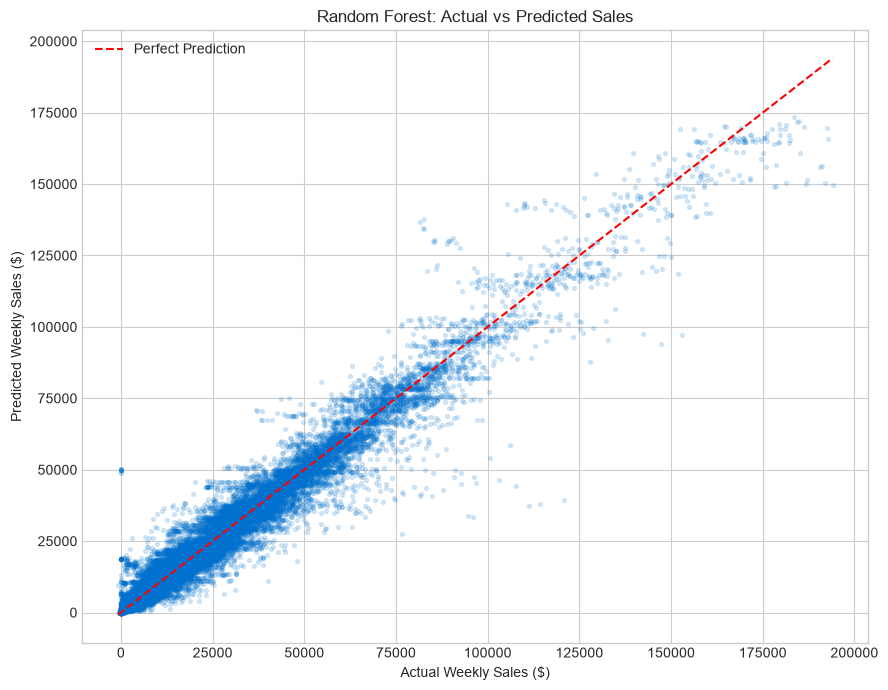

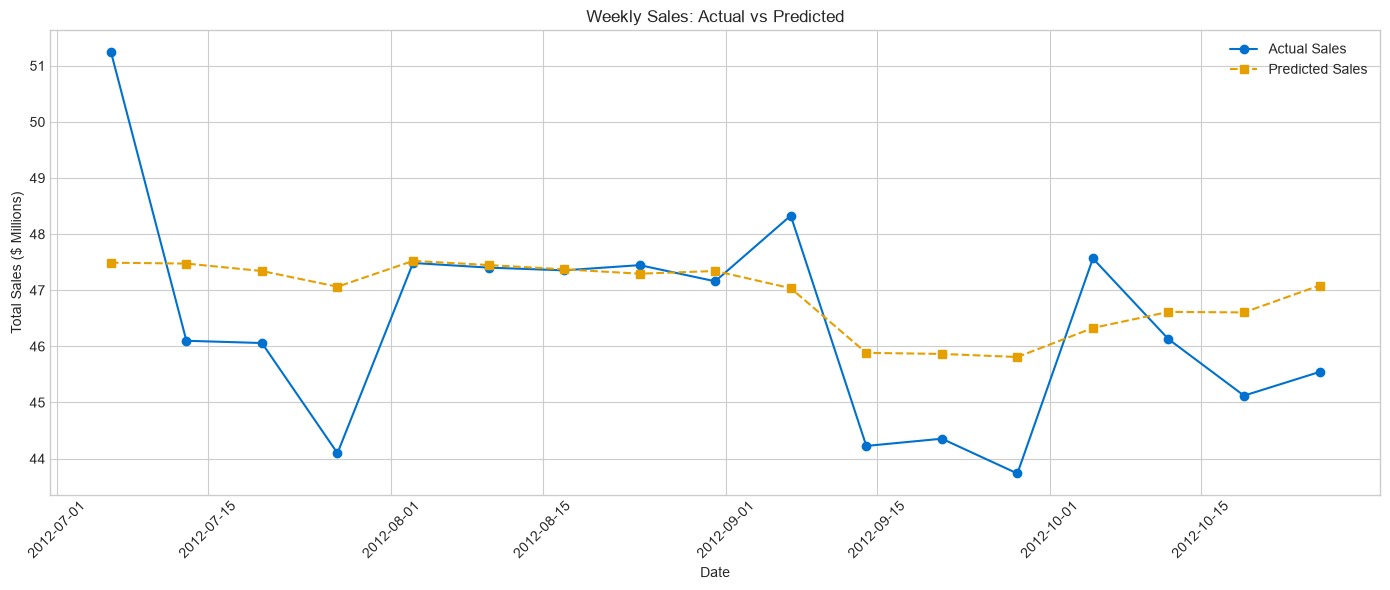

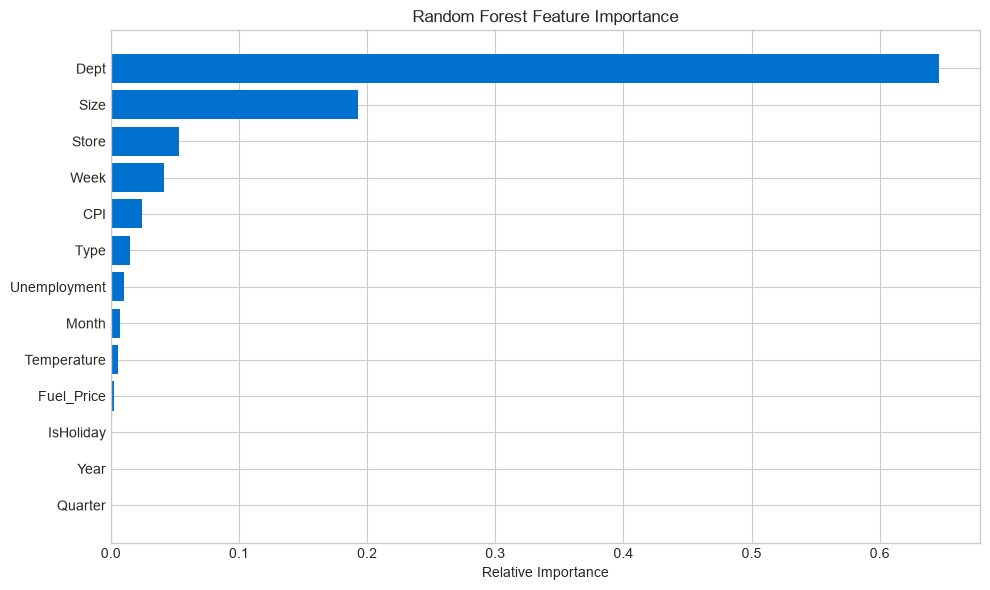

,Feature,Importance
1,Dept,0.645942
3,Size,0.192476
0,Store,0.053353
11,Week,0.041827
6,CPI,0.024528
2,Type,0.014608
7,Unemployment,0.010449
10,Month,0.006782
4,Temperature,0.005798
5,Fuel_Price,0.002440


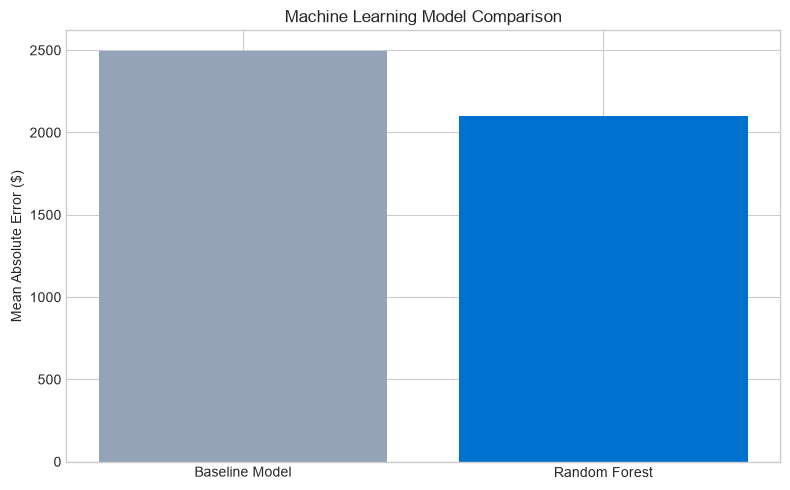


All machine learning charts created!
All model results exported!
MACHINE LEARNING SECTION COMPLETED!


In [7]:
# ==========================================
# MACHINE LEARNING - VISUALIZATION & EXPORT
# ==========================================

import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

os.makedirs("visualizations", exist_ok=True)
os.makedirs("results", exist_ok=True)

# 1. Actual vs Predicted Sales

plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.15,
    s=8,
    color="#0071CE"
)

minimum = min(y_test.min(), rf_predictions.min())
maximum = max(y_test.max(), rf_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Random Forest: Actual vs Predicted Sales")
plt.xlabel("Actual Weekly Sales ($)")
plt.ylabel("Predicted Weekly Sales ($)")
plt.legend()
plt.tight_layout()

plt.savefig(
    "visualizations/actual_vs_predicted.png",
    dpi=300
)

plt.show()

# 2. Weekly Sales Forecast Comparison

prediction_results = test_data[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].copy()

prediction_results = prediction_results.rename(
    columns={"Weekly_Sales": "Actual_Sales"}
)

prediction_results["Predicted_Sales"] = rf_predictions
prediction_results["Baseline_Sales"] = baseline_predictions

weekly_forecast = prediction_results.groupby("Date")[
    ["Actual_Sales", "Predicted_Sales"]
].sum()

plt.figure(figsize=(14, 6))

plt.plot(
    weekly_forecast.index,
    weekly_forecast["Actual_Sales"] / 1e6,
    marker="o",
    label="Actual Sales",
    color="#0071CE"
)

plt.plot(
    weekly_forecast.index,
    weekly_forecast["Predicted_Sales"] / 1e6,
    marker="s",
    linestyle="--",
    label="Predicted Sales",
    color="#E69F00"
)

plt.title("Weekly Sales: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Total Sales ($ Millions)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "visualizations/weekly_sales_forecast.png",
    dpi=300
)

plt.show()

# 3. Feature Importance Analysis

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
    color="#0071CE"
)

plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.xlabel("Relative Importance")
plt.tight_layout()

plt.savefig(
    "visualizations/feature_importance.png",
    dpi=300
)

plt.show()

display(feature_importance)

# 4. Model Performance Comparison

plt.figure(figsize=(8, 5))

plt.bar(
    model_results["Model"],
    model_results["MAE"],
    color=["#94A3B8", "#0071CE"]
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Mean Absolute Error ($)")
plt.tight_layout()

plt.savefig(
    "visualizations/model_comparison.png",
    dpi=300
)

plt.show()

# 5. Export Results

model_results.to_csv(
    "results/model_performance.csv",
    index=False
)

prediction_results.to_csv(
    "results/sales_predictions.csv",
    index=False
)

feature_importance.to_csv(
    "results/feature_importance.csv",
    index=False
)

weekly_forecast.to_csv(
    "results/weekly_forecast.csv"
)

print("\nAll machine learning charts created!")
print("All model results exported!")
print("MACHINE LEARNING SECTION COMPLETED!")

In [8]:
# Export cleaned dataset for Tableau

from pathlib import Path

tableau_folder = Path("tableau")
tableau_folder.mkdir(exist_ok=True)

walmart.to_csv(
    tableau_folder / "walmart_tableau_data.csv",
    index=False
)

print("Tableau dataset exported successfully!")
print("Total Records:", len(walmart))
print("Total Columns:", len(walmart.columns))

Tableau dataset exported successfully!
Total Records: 421570
Total Columns: 19
